# 🌙 Cvičení: Hustotní shlukování DBSCAN na datech dvou půlměsíců (make_moons)

> **Oficiální zadání cvičení:**  
> *Using the `make_moons` method from the datasets module of the Scikit-learn library, create a dataset of 500 observations. The dataset should have a noise of 0.10. Assign the random seed to get the same results every time you run it.*  
> *Perform data standardization.*  
> *Using the `DBSCAN` class, create a model that will perform data clustering. Select appropriate values for the hyperparameters.*  
> *Assign cluster labels for each observation to the `dbscan_labels` variable.*  
> *Generate a graph to represent the dataset so that it illustrates which clusters each point belongs to.*

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans
from sklearn.datasets import make_moons
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# Nastavení stylu grafů
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
print('Knihovny úspěšně importovány.')

Knihovny úspěšně importovány.


## 1. Generování datasetu make_moons dle zadání

Vytvoříme syntetický 2D dataset se dvěma propletenými půlměsíci o 500 pozorováních s úrovní šumu `0.10` a fixovaným seedem `random_state=42`.

In [2]:
# 1. Generování datasetu dle zadání
n_samples = 500
noise = 0.10
random_state = 42

X, y_true = make_moons(n_samples=n_samples, noise=noise, random_state=random_state)

print(f'Rozměry datasetu X: {X.shape}')
print(f'Prvních 5 vzorků:\n{X[:5]}')

Rozměry datasetu X: (500, 2)
Prvních 5 vzorků:
[[ 0.83067643 -0.40993581]
 [ 0.79835529  0.83761218]
 [ 1.05046846 -0.48516193]
 [-0.25814276  0.98000844]
 [ 0.3306816   1.14763307]]


## 2. Standardizace dat (StandardScaler)

DBSCAN měří eukleidovské vzdálenosti. Aby obě dimenze měly jednotkový rozptyl a nulový průměr, provedeme standardizaci.

In [3]:
# 2. Standardizace dat
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f'Průměry po standardizaci: {X_scaled.mean(axis=0).round(4)}')
print(f'Směrodatné odchylky: {X_scaled.std(axis=0).round(4)}')

Průměry po standardizaci: [-0. -0.]
Směrodatné odchylky: [1. 1.]


## 3. Analytické stanovení hyperparametrů (k-NN Distance Elbow Method)

Pro 2D prostor volíme `min_samples = 8` (robustní vůči šumu $0.10$). Optimální parametr $\varepsilon$ nalezneme vykreslením seřazených vzdáleností k 8. nejbližšímu sousedovi dle metodiky kurzu (slajd 16).

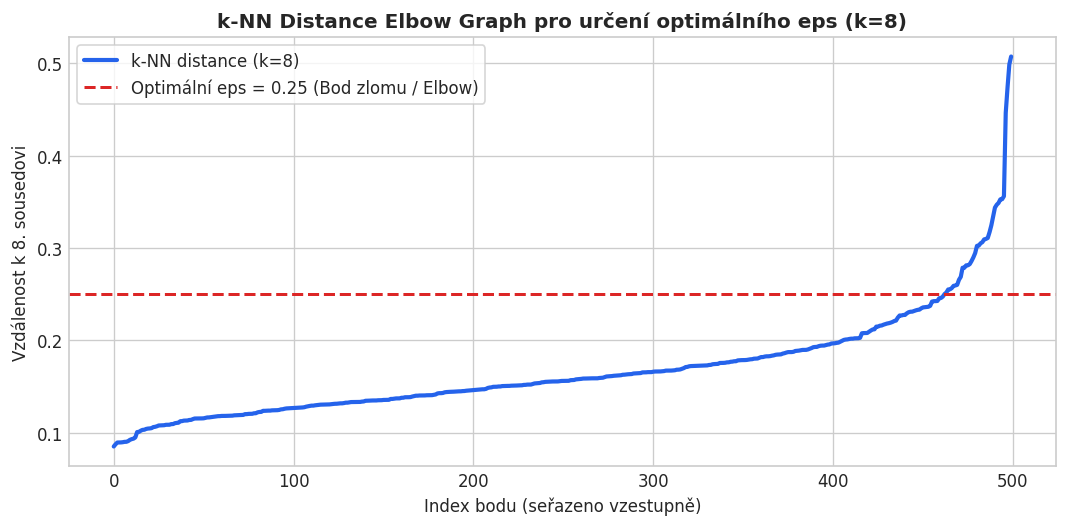

Bod zlomu (elbow) leží v rozmezí eps = 0.22 až 0.28. Volíme eps = 0.25.


In [4]:
k = 8
knn = NearestNeighbors(n_neighbors=k)
knn.fit(X_scaled)
distances, _ = knn.kneighbors(X_scaled)
sorted_distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 4.5))
plt.plot(range(len(sorted_distances)), sorted_distances, color='#2563eb', lw=2.5, label='k-NN distance (k=8)')
plt.axhline(0.25, color='#dc2626', ls='--', lw=1.8, label='Optimální eps = 0.25 (Bod zlomu / Elbow)')
plt.title('k-NN Distance Elbow Graph pro určení optimálního eps (k=8)', fontsize=12, fontweight='bold')
plt.xlabel('Index bodu (seřazeno vzestupně)', fontsize=10)
plt.ylabel('Vzdálenost k 8. sousedovi', fontsize=10)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

print('Bod zlomu (elbow) leží v rozmezí eps = 0.22 až 0.28. Volíme eps = 0.25.')

## 4. Vytvoření a trénování modelu DBSCAN

Inicializujeme model `DBSCAN(eps=0.25, min_samples=8)` a přiřadíme predikovaná označení shluků do proměnné `dbscan_labels` přesně podle zadání.

In [5]:
# 3. Model DBSCAN s vhodně zvolenými hyperparametry
dbscan = DBSCAN(eps=0.25, min_samples=8)

# 4. Přiřazení označení shluků pro každé pozorování do proměnné dbscan_labels
dbscan_labels = dbscan.fit_predict(X_scaled)

# Statistické vyhodnocení
unique_clusters = set(dbscan_labels) - {-1}
n_clusters = len(unique_clusters)
n_noise = int(np.sum(dbscan_labels == -1))
ari = adjusted_rand_score(y_true, dbscan_labels)

print(f'Nalezeno shluků: {n_clusters}')
print(f'Počet šumových bodů (outlierů, label -1): {n_noise} ({n_noise / len(X) * 100:.2f} %)')
print(f'Adjusted Rand Index (ARI): {ari:.4f} (vynikající shoda se skutečnou strukturou)')

Nalezeno shluků: 2
Počet šumových bodů (outlierů, label -1): 5 (1.00 %)
Adjusted Rand Index (ARI): 0.9801 (vynikající shoda se skutečnou strukturou)


## 5. Grafická reprezentace datasetu a shluků (dle zadání)

Vykreslíme scatter plot se zvýrazněním nalezených shluků a odlišením šumových bodů označených hodnotou `-1`.

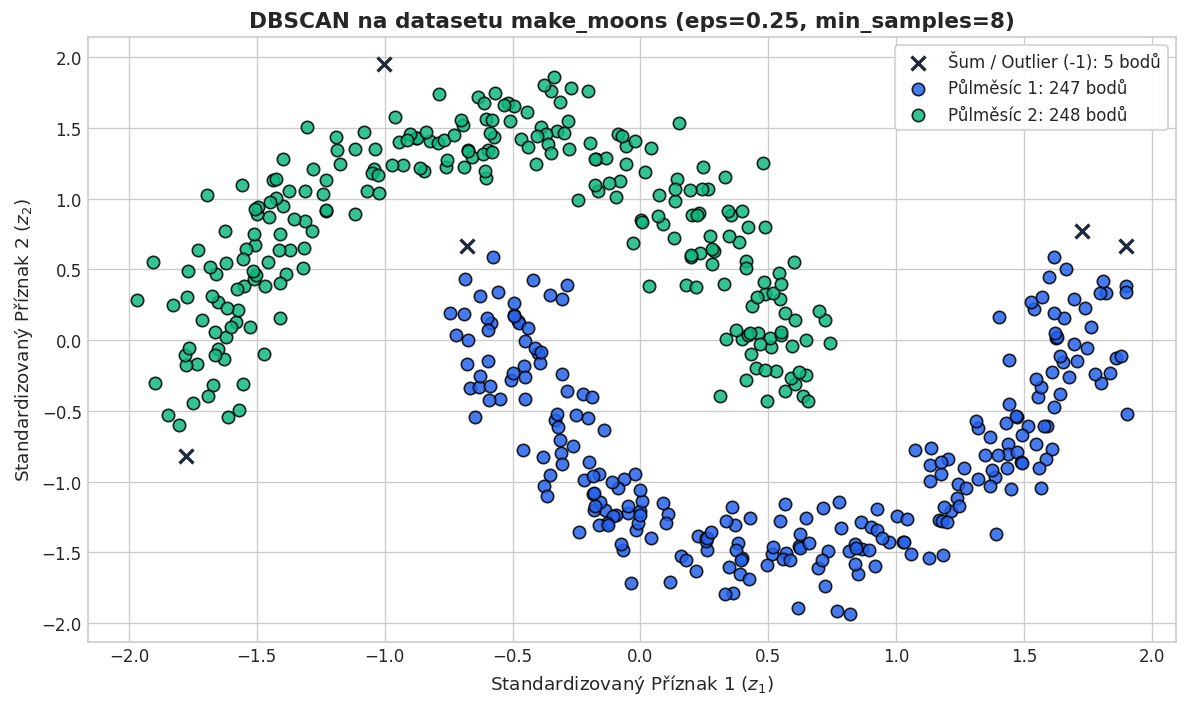

In [6]:
# 5. Generování grafu reprezentujícího dataset a příslušnost ke shlukům
plt.figure(figsize=(10, 6))
palette = ['#2563eb', '#10b981']

for cluster_id in sorted(list(set(dbscan_labels))):
    mask = (dbscan_labels == cluster_id)
    if cluster_id == -1:
        plt.scatter(
            X_scaled[mask, 0], X_scaled[mask, 1],
            c='#1e293b', marker='x', s=70, linewidths=2,
            label=f'Šum / Outlier (-1): {mask.sum()} bodů'
        )
    else:
        plt.scatter(
            X_scaled[mask, 0], X_scaled[mask, 1],
            c=palette[cluster_id], marker='o', s=55, edgecolors='black', alpha=0.85,
            label=f'Půlměsíc {cluster_id + 1}: {mask.sum()} bodů'
        )

plt.title('DBSCAN na datasetu make_moons (eps=0.25, min_samples=8)', fontsize=13, fontweight='bold')
plt.xlabel('Standardizovaný Příznak 1 ($z_1$)', fontsize=11)
plt.ylabel('Standardizovaný Příznak 2 ($z_2$)', fontsize=11)
plt.legend(frameon=True, facecolor='white', framealpha=0.9, loc='upper right')
plt.tight_layout()
plt.show()

## 6. Srovnání se selháním K-Means na nekonvexních datech

K-Means minimalizuje součet čtverců vzdáleností k těžištím (WCSS), což nutně vede k Voroného buňkám (lineárním hranicím). Půlměsíce tak přeřízne na dvě sférické poloviny.

C:\Users\xeen\AppData\Local\Temp\ipykernel_28044\3245254945.py:27: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\xeen\AppData\Local\Temp\ipykernel_28044\3245254945.py:27: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\xeen\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\xeen\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


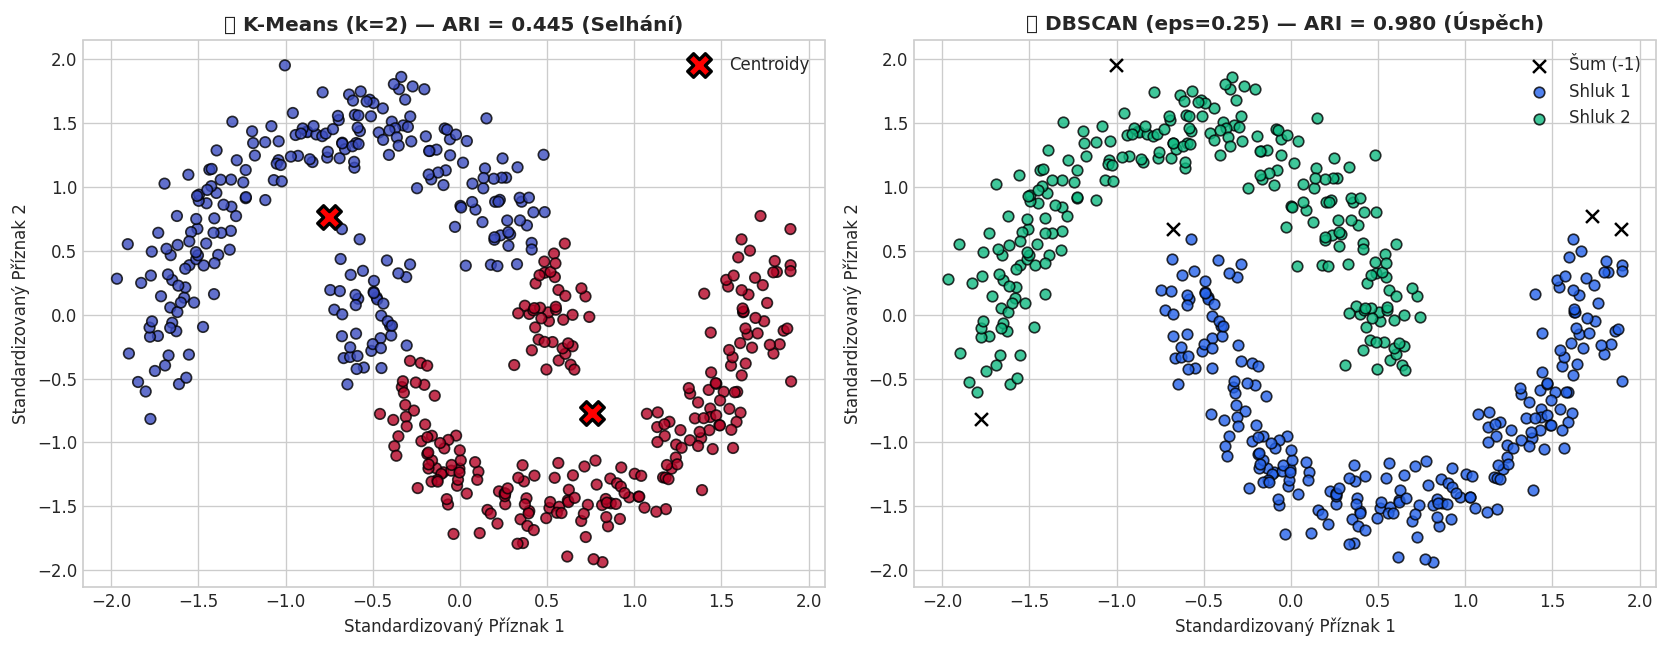

In [7]:
km = KMeans(n_clusters=2, random_state=42, n_init=10)
km_labels = km.fit_predict(X_scaled)
km_ari = adjusted_rand_score(y_true, km_labels)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Graf 1: K-Means
ax1.scatter(X_scaled[:, 0], X_scaled[:, 1], c=km_labels, cmap='coolwarm', s=40, edgecolors='k', alpha=0.8)
ax1.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], c='red', marker='X', s=200, edgecolors='black', lw=2, label='Centroidy')
ax1.set_title(f'❌ K-Means (k=2) — ARI = {km_ari:.3f} (Selhání)', fontweight='bold')
ax1.set_xlabel('Standardizovaný Příznak 1')
ax1.set_ylabel('Standardizovaný Příznak 2')
ax1.legend()

# Graf 2: DBSCAN
for cid in sorted(list(set(dbscan_labels))):
    m = (dbscan_labels == cid)
    if cid == -1:
        ax2.scatter(X_scaled[m, 0], X_scaled[m, 1], c='black', marker='x', s=60, label='Šum (-1)')
    else:
        ax2.scatter(X_scaled[m, 0], X_scaled[m, 1], c=palette[cid], s=40, edgecolors='k', alpha=0.8, label=f'Shluk {cid+1}')
ax2.set_title(f'✅ DBSCAN (eps=0.25) — ARI = {ari:.3f} (Úspěch)', fontweight='bold')
ax2.set_xlabel('Standardizovaný Příznak 1')
ax2.set_ylabel('Standardizovaný Příznak 2')
ax2.legend()

plt.tight_layout()
plt.show()

## 7. Typologie bodů DBSCAN: Core, Border a Noise

DBSCAN kategorizuje každý bod do jedné ze tří tříd:
1. **Core point (Jádrový bod):** Má ve svém $\varepsilon$-okolí alespoň `min_samples` bodů.
2. **Border point (Hraniční bod):** Má méně než `min_samples` bodů, ale leží v dosahu jádrového bodu.
3. **Noise (Šum):** Neleží v dosahu žádného jádrového bodu.

Jádrových bodů (Core): 462 (92.4 %)
Hraničních bodů (Border): 33 (6.6 %)
Šumových bodů (Noise): 5 (1.0 %)


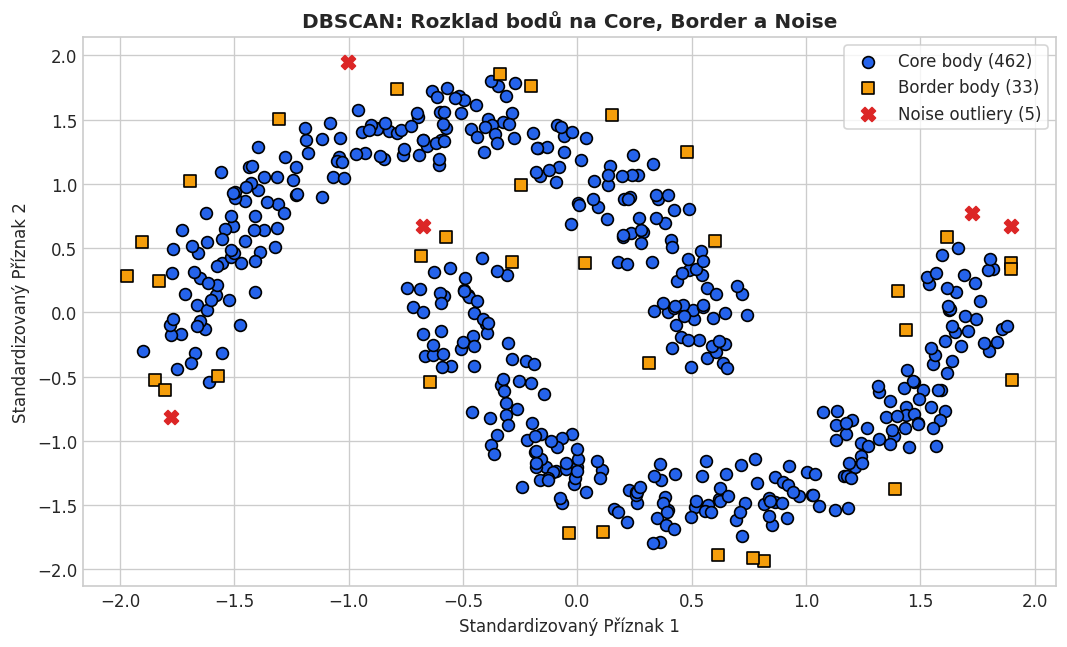

In [8]:
core_mask = np.zeros_like(dbscan_labels, dtype=bool)
core_mask[dbscan.core_sample_indices_] = True
border_mask = (~core_mask) & (dbscan_labels != -1)
noise_mask = (dbscan_labels == -1)

print(f'Jádrových bodů (Core): {core_mask.sum()} ({core_mask.sum()/len(X)*100:.1f} %)')
print(f'Hraničních bodů (Border): {border_mask.sum()} ({border_mask.sum()/len(X)*100:.1f} %)')
print(f'Šumových bodů (Noise): {noise_mask.sum()} ({noise_mask.sum()/len(X)*100:.1f} %)')

plt.figure(figsize=(9, 5.5))
plt.scatter(X_scaled[core_mask, 0], X_scaled[core_mask, 1], c='#2563eb', s=50, edgecolors='k', label=f'Core body ({core_mask.sum()})')
plt.scatter(X_scaled[border_mask, 0], X_scaled[border_mask, 1], c='#f59e0b', s=45, edgecolors='k', marker='s', label=f'Border body ({border_mask.sum()})')
plt.scatter(X_scaled[noise_mask, 0], X_scaled[noise_mask, 1], c='#dc2626', s=70, marker='X', label=f'Noise outliery ({noise_mask.sum()})')
plt.title('DBSCAN: Rozklad bodů na Core, Border a Noise', fontsize=12, fontweight='bold')
plt.xlabel('Standardizovaný Příznak 1')
plt.ylabel('Standardizovaný Příznak 2')
plt.legend(frameon=True, loc='upper right')
plt.tight_layout()
plt.show()